# Урок 17. Когда одного пятна мало

[План курса](../../README_ru.md)

На образце две синие бусины со светлым промежутком. У модели вместо них одно широкое пятно и почти прозрачная крошка в стороне. Широкое пятно можно передвигать и ослаблять. Но у его горизонтального среза одна вершина, а у образца две. Иногда следующим шагом становится изменение самого списка гауссиан.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo
lang = "ru"

## Один старт, несколько продолжений

Камера, цвет и фон закреплены. Слева образец, справа модель. Отдельные действия дают клон выбранного пятна, заменяют его двумя дочерними, убирают слабые пятна или уменьшают непрозрачность всех сразу. По очереди можно сравнить эти действия из одной исходной сцены. Обычный шаг градиента двигает центры по горизонтали и меняет непрозрачность.

У каждого сравнения есть три разных числа. MSE говорит о цвете 33 × 33 пикселей. Число пятен — о длине списка. Размер в байтах учитывает только сохранённые числовые параметры в формате float32. Если действие получилось дорогим и ухудшило картинку, это тоже результат опыта.

Квадратная рамка на обоих кадрах отмечает пиксель измерения. Ползунок столбца передвигает её по строке 16. При первом открытии она стоит в просвете, и разность красного канала равна примерно −0.463.

In [2]:
display(demo.experiment(17, "ru"))

## В середине должна проступить белая полоска

У прошлого опыта была хорошая подсказка. Даже неудачная начальная модель уже содержала столько предметов, сколько требовалось для ответа. Здесь число свободных деталей само по себе стало неизвестным. При взгляде на весь кадр синее облачко может показаться вполне похожим на две бусины. Возьмём одну горизонтальную строку и пройдём через обе середины. Теперь вместо общего впечатления будут три конкретных места, где можно сравнить цвет.

Центр камеры находится в нуле, фокус равен 42 пикселям. Оба центра образца лежат на глубине 4 м при $X=-0.54$ и $X=0.42$ м. Значит, середины бусин окажутся в столбцах $16+42(-0.54)/4=10.33$ и $16+42(0.42)/4=20.41$. По вертикали обе имеют $Y=0$, так что проходит строка 16. Выберем столбцы 10, 16 и 20. Первое и третье измерения близки к центрам бусин, второе попадает в просвет. В NumPy адрес записывается в порядке «строка, столбец, канал». Например, `image[16, 10, 0]` означает красную яркость в левой бусине. На белом фоне красная яркость равна единице. Синяя краска поглощает много красного, поэтому след бусины на графике красного канала выглядит как **впадина**.

| Красный канал, строка 16 | Левый центр | Просвет | Правый центр |
|---|---:|---:|---:|
| Две бусины на образце | 0.215 | 0.806 | 0.219 |
| Исходная модель | 0.453 | 0.344 | 0.531 |

Левую и правую части предстоит затемнить, а середину одновременно осветлить. У широкого пятна середина сейчас самая тёмная. Если прибавить непрозрачность повсюду, края потемнеют, но просвет станет ещё хуже. Если потянуть пятно вправо, улучшение на одной бусине придётся оплатить ошибкой на другой. Эта тройка чисел рассказывает о **форме** промаха больше, чем одна средняя ошибка. На следующем рисунке остаётся вся строка. Три отмеченных столбца позволяют читать её даже там, где линии почти сливаются.

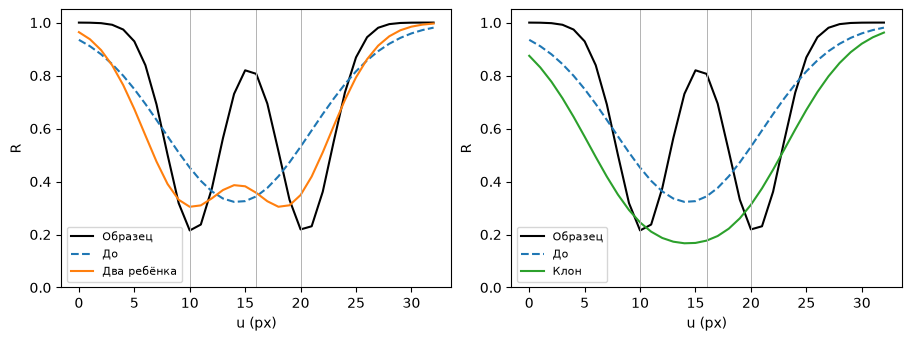

In [3]:
camera = sr.translated_camera(0, focal=42)
start = sr.density_scene()
cases = [sr.density_scene(True), start, sr.density_edit(start, "split"), sr.density_edit(start, "clone")]
names = (["Образец", "До", "Два ребёнка", "Клон"] if lang == "ru"
         else ["Target", "Before", "Two children", "Clone"])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), constrained_layout=True)
for ax, indices in zip(axes, [(0, 1, 2), (0, 1, 3)]):
    for i in indices:
        image = sr.render_scene(cases[i], camera, 33, 33)
        ax.plot(image[16, :, 0], ["k-", "C0--", "C1-", "C2-"][i], label=names[i])
    for u in [10, 16, 20]:
        ax.axvline(u,color=".7",lw=.7)
    ax.set(xlabel="u (px)", ylabel="R", ylim=(0,1.05)); ax.legend(fontsize=8)
plt.show()

## Шаг внутри списка

Сначала в списке два пятна. У большого $x=-0.16$, горизонтальная ширина $s_x=0.63$, центральная непрозрачность $o=0.77$. Сдвиг на малое расстояние меняет RGB кадра и его ошибку. Для двух производных делаем по два замера из одного и того же исходного состояния, как в прошлом уроке. Получаем $g_x\approx-0.00304635$ единицы MSE на единицу длины и $g_o\approx0.00834045$ на единицу непрозрачности.

При размере шага $\eta=3$ новая координата $x'=-0.16-3(-0.00304635)\approx-0.15086$. Новая непрозрачность $o'=0.77-3(0.00834045)\approx0.74498$. Сдвиг получается вправо, пятно чуть светлеет на белом фоне. Шаг для маленького пятна считается по его собственным двум производным. После одновременного обновления MSE уменьшается с $0.00467723$ до $0.00446188$. Индексы 0 и 1 по-прежнему указывают на те же два пятна. Градиент числа с индексом 0 не создаёт строку с индексом 2.

In [4]:
initial = sr.density_scene()
print(np.round(sr.density_gradients(initial), 7))
updated = sr.density_step(initial)
print(updated["splats"][0]["center"], updated["splats"][0]["opacity"])
assert len(initial["splats"]) == len(updated["splats"]) == 2
assert sr.density_loss(updated) < sr.density_loss(initial)

[[-3.0463e-03  8.3405e-03]
 [ 4.5300e-05 -5.5900e-05]]
[-0.1508609595795733, 0, 4] 0.7449786379339152


### Как узнать, есть ли смысл ещё двигать центр

Это удобное место для ошибки в диагнозе. MSE после первого шага уменьшилась. Значит ли это, что через достаточно много шагов посередине обязательно появится белая полоска? По величине первого шага этого не узнать. Упражнение сначала разрешало менять только центр по горизонтали и непрозрачность каждого пятна. Масштабы закреплены. Градиенты обоих центров и обеих непрозрачностей вычисляются **до** изменения любой строки. Иначе второй производной досталась бы уже другая сцена, и сумма перестала бы описывать один и тот же начальный кадр.

Посмотрим, что значит положительная производная по непрозрачности у широкого пятна. Она равна примерно 0.00834 на единицу $o$. При небольшом увеличении $o$ на 0.001 ошибка выросла бы примерно на $0.00834\cdot0.001=0.00000834$. Снижение $o$ всё-таки выгодно в среднем, хотя левой бусине прямо сейчас хотелось бы прибавить синего. Получается компромисс по всем пикселям, включая фон. После двенадцати обычных шагов ошибка той же модели составляет около 0.004002. Движение параметров помогло. Форма, которую может принять один широкий колокол, осталась ограниченной.

Исключать из рассуждения маленькое второе пятно тоже нельзя. Оно формально уже даёт ещё одну вершину. В начале оно висит выше бусин и почти прозрачно. Мы двигаем центры только по горизонтали, так что вниз на линию бусин оно вообще не опустится. Его градиент по горизонтали почти в семьдесят раз слабее, чем у большого. Если разрешить перемещение по вертикали, независимые масштабы и другой старт, ограничения эксперимента изменятся. По картинке этого конкретного запуска можно судить о механике операций. Утверждать, будто пара произвольно обучаемых гауссиан в принципе не способна изобразить две бусины, было бы странно. Из двух гауссиан как раз и сделан наш образец.

## Клон затемняет, разделение меняет форму

**Клон** добавляет в конец копию центра, формы, цвета и непрозрачности. В центре исходного пятна $\alpha=0.77$, оно пропускало $1-0.77=0.23$ света фона. Два одинаковых слоя пропускают $0.23\cdot0.23=0.0529$, суммарная непрозрачность $1-0.0529=0.9471$. Поэтому одинаковые координаты не означают ту же картинку. Слишком тёмная синяя область увеличивает MSE до $0.01214659$. Дальше параметры двух копий можно менять независимо.

**Разделение** удаляет широкого родителя, а взамен добавляет двух детей. Чтобы опыт повторялся, положим их симметрично по горизонтали. Сначала считаем смещение $0.65\cdot0.63=0.4095$, затем центры $-0.16-0.4095=-0.5695$ и $-0.16+0.4095=0.2495$. Все три масштаба делим на $1.6$. Например, горизонтальный $0.63/1.6=0.39375$. Цвет и $o$ дети получают от родителя. Две вершины уже угадываются, а MSE становится $0.00347211$. При другом образце или другом исходном пятне такое деление способно ухудшить изображение.

И клон, и разделение увеличили список с двух строк до трёх. В первом случае в списке остаются родитель и его копия. Во втором родителя больше нет, есть два смещённых пятна и прежняя крошка.

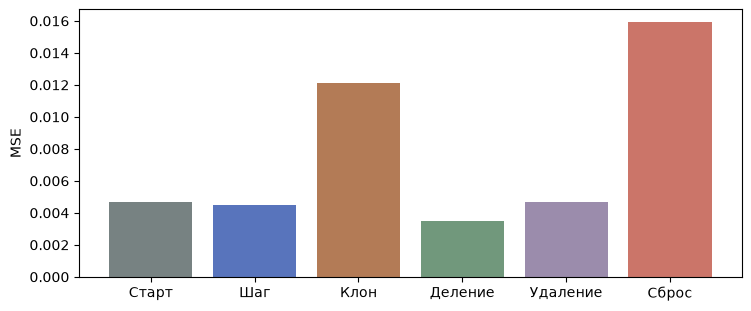

In [5]:
fig = demo.density_chart("ru")
display(fig)
plt.close(fig)

### Можно ли поделить непрозрачность без скачка?

Два клона с прежней непрозрачностью почти перекрыли фон. Первая догадка — отдать каждому половину прежнего значения. В центре это $0.77/2=0.385$. Остаток фона теперь $(1-0.385)^2=0.378225$, хотя до копирования оставалось 0.23. Полупрозрачные слои закрывают в том числе друг друга. Деление одного числа пополам не сохраняет итоговый цвет.

В центре совпадающих пятен можно решить задачу в обратную сторону. Оставим двум равным слоям ровно прежнее пропускание $T=0.23$. Пусть $a$ — новая непрозрачность каждого. Тогда

$$
\begin{aligned}
(1-a)(1-a)&=0.23,\\
1-a&=\sqrt{0.23}\approx0.47958,\\
a&=1-0.47958\approx0.52042.
\end{aligned}
$$

Положительный корень выбран потому, что доля пропущенного света лежит между нулём и единицей. На этом месте математика вроде бы закончилась. Но центр — только один адрес. На таком расстоянии от центра, где вес гауссианы упал до половины, у старой модели $\alpha=0.77\cdot0.5=0.385$. У пары за раз закрашивается доля $1-(1-0.52042\cdot0.5)^2\approx0.4527$. По краям новая пара всё ещё темнее, хотя в центре подобрана точно. Так даже аккуратное копирование меняет профиль до любого следующего шага оптимизатора.

Расхождение появилось из-за произведения двух пропусканий. У операции нет постоянного коэффициента, который одновременно привёл бы к прежнему ответу во всех точках мягкого следа при той же форме двух детей. Разделение меняет ещё и их центры с масштабами. На графике в просвете после немедленного разделения по-прежнему слишком мало красного, примерно 0.357 против 0.806 у образца. Теперь у двух детей есть независимые направления сдвига. Изменилась возможность **последующих** шагов, и это видно только после повторной подгонки.

In [6]:
parent_o = .77
child_o = 1 - np.sqrt(1-parent_o)
for w in (1, .5, .1, 0):
    old = parent_o*w
    pair = 1 - (1-child_o*w)**2
    print(f"w={w:.1f}   old={old:.5f}   pair={pair:.5f}   Δ={pair-old:+.5f}")

w=1.0   old=0.77000   pair=0.77000   Δ=+0.00000
w=0.5   old=0.38500   pair=0.45271   Δ=+0.06771
w=0.1   old=0.07700   pair=0.10138   Δ=+0.02438
w=0.0   old=0.00000   pair=0.00000   Δ=+0.00000


## Удаление и сброс — две разные истории

**Удаление, или pruning**, вычёркивает пятно целиком. Наш порог $0.03$ относится к непрозрачности в центре. У крошки $o=0.015<0.03$, поэтому она исчезает. От большого пятна отказываться рано. Список становится короче, а ошибка почти та же, $0.00467882$. Она слегка **выросла**. Маленькое влияние и нулевое влияние — разные вещи.

**Сброс непрозрачности** оставляет центры и формы на местах. Новое значение $o'=\min(o,0.01)$ означает меньшее из прежнего $o$ и одной сотой. Например, $0.77$ станет $0.01$, а $0.004$ останется $0.004$. Пока пятна слабы, через них проходит больше света и вклад скрытого слоя может стать видимее. Оптимизация заново наращивает полезные непрозрачности. Непосредственно после сброса картинка почти белая, MSE $0.01592582$. Если тут же применить порог удаления $0.03$, не останется ни одного пятна. В полном обучении важны порядок и расписание операций.

In [7]:
for action in ("clone","split","prune","reset"):
    scene = sr.density_edit(initial, action)
    n = len(scene["splats"])
    print(f"{action:6s} N={n}, bytes={56*n}, MSE={sr.density_loss(scene):.8f}")
assert len(sr.density_edit(sr.density_edit(initial, "reset"), "prune")["splats"]) == 0

clone  N=3, bytes=168, MSE=0.01214659
split  N=3, bytes=168, MSE=0.00347211
prune  N=1, bytes=56, MSE=0.00467882
reset  N=2, bytes=112, MSE=0.01592582


### Удаление пятна глазами другой камеры

У крошки непрозрачность 0.015. Даже в собственном центре она получает не больше этой доли цвета. Если перед ней уже осталась лишь десятая часть света, вес в пикселе не превысит $0.1\cdot0.015=0.0015$. Это даёт понятный повод проверить удаление, но не говорит, сколько оно изменит **весь кадр**. Большое бледное пятно касается многих пикселей, маленькое может попасть прямо на тонкую контрастную деталь. Кроме того, при обходе камеры передний слой может уйти в сторону и открыть закрытый ранее след.

Сравним исходник, немедленный клон, немедленное разделение и удаление при двух положениях камеры. Геометрия бусин известна, поэтому целевой кадр каждого ракурса можно получить независимо. Действия выбирались из фронтального изображения. Вторую камеру перенесём на $+0.6$ м, сохранив фокус и направление. Здесь она служит проверкой одного решения и в расчёт градиентов не входит. Для удаления фронтальная ошибка вырастает примерно с 0.00467723 до 0.00467882. У другой камеры с 0.00420203 до 0.00420206. При округлении до трёх знаков разница вовсе потеряется. Две сцены при этом остались разными, и расходы на одно пятно действительно исчезли.

Ещё одна честная развилка — считать цену хранения частью задачи. Пусть к MSE для выбора добавляется условная плата $\lambda N$, где $N$ — целое число пятен, $\lambda$ — допустимая плата в единицах средней ошибки за дополнительную строку. Получается оценка $J=L+\lambda N$. Никакой новый пиксель от этого не появляется. Такое правило лишь определяет, что означает «лучше» в конкретном опыте. У немедленного разделения выигрыш в MSE равен $0.00467723-0.00347211=0.00120512$ при одной дополнительной строке. Плата 0.0005 оставляет запас в пользу разделения. Плата 0.002 делает прежнюю модель предпочтительнее. Этот расчёт сравнивает два готовых состояния. Если после правки есть бюджет ещё на двенадцать шагов, сравнивать нужно заново после этих шагов.

В исходной статье плотность меняют по накопленному сигналу и правилам размера и непрозрачности. Плата за строку здесь нужна только для нашего явного выбора. Градиент $J$ по координате при неизменном числе строк совпадает с градиентом $L$. Постоянная добавка $\lambda N$ никак не подскажет существующему центру, что пора родить соседа.

In [8]:
held_camera = sr.translated_camera(.6, focal=42)
held_target = sr.render_scene(sr.density_scene(True), held_camera, 33, 33)
for action in ("unchanged", "clone", "split", "prune", "reset"):
    candidate = initial if action == "unchanged" else sr.density_edit(initial, action)
    held_frame = sr.render_scene(candidate, held_camera, 33, 33)
    held_mse = np.mean((held_frame-held_target)**2)
    before_loss = sr.density_loss(candidate)
    fitted = candidate
    for _ in range(12):
        fitted = sr.density_step(fitted)
    print(f"{action:9} N={len(candidate['splats'])}  train={before_loss:.8f}  "
          f"held={held_mse:.8f}  train@12={sr.density_loss(fitted):.8f}")

unchanged N=2  train=0.00467723  held=0.00420203  train@12=0.00400165


clone     N=3  train=0.01214659  held=0.01042208  train@12=0.00407204


split     N=3  train=0.00347211  held=0.00310032  train@12=0.00282129
prune     N=1  train=0.00467882  held=0.00420206  train@12=0.00400429
reset     N=2  train=0.01592582  held=0.01600684  train@12=0.00411495


## Как решение принимает программа

В одном автоматическом проходе опыта сначала считаем все градиенты в прежней сцене. Для каждого пятна с $o<0.03$ выбираем удаление. У остальных сравниваем модуль горизонтального градиента с порогом $0.001$. Для большого пятна $|-0.00304635|>0.001$. Так программа замечает участок, где движение центра может заметно изменить ошибку. Это чувствительность к сдвигу, а не гарантия, что именно там лежит недостающая деталь.

Теперь нужен выбор между копией и двумя детьми. В этом опыте горизонтальный масштаб больше $0.32$ означает широкое пятно. При $0.63>0.32$ выбирается деление. Для достаточно узкого пятна с таким же сильным сигналом выбирался бы клон. Запас ограничен 16 пятнами, чтобы каждый шаг удобно разбирать. После первого автоматического прохода широкое пятно заменено двумя, слабое удалено, общее число снова равно двум. MSE уже другая, около $0.00348773$. Одного счётчика недостаточно, чтобы заметить перестройку сцены.

У авторов 3DGS сигнал копится для **видимых** пятен по нескольким шагам. Берутся длины двумерных градиентов по экранному центру и усредняются по наблюдениям. Размер сравнивается с масштабом сцены. При разделении положение детей случайно выбирается относительно формы и ориентации родителя. Код также умеет удалять чрезмерно крупные следы. Наша однокамерная версия использует производную по мировой $x$, фиксированное смещение детей и явные кнопки. Численные пороги из этого примера относятся только к его координатам и loss. [Алгоритм в статье](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) и [операции над параметрами в исходниках](https://github.com/graphdeco-inria/gaussian-splatting/blob/main/scene/gaussian_model.py).

In [9]:
adaptive = sr.density_pass(initial)
print([(s["center"][0],s["scales"][0],s["opacity"]) for s in adaptive["splats"]])
assert len(adaptive["splats"]) == len(initial["splats"])
assert sr.density_loss(adaptive) < sr.density_loss(initial)
for _ in range(8):
    adaptive = sr.density_step(adaptive)
print("8 steps:", sr.density_loss(adaptive))

[(-0.5695, 0.39375, 0.77), (0.24950000000000003, 0.39375, 0.77)]
8 steps: 0.0028990938514448354


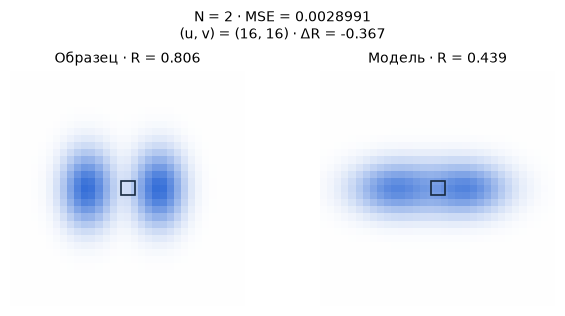

In [10]:
fig = demo.density_figure("ru", operation="adaptive", steps=8)
display(fig)
plt.close(fig)

## Опыты и разбор

Сколько памяти прибавил один клон? Почему итоговую разницу в занятой памяти видеокарты нельзя получить из одного этого числа?

<details><summary>Разбор</summary>

У пятна три координаты, три масштаба, четыре компоненты кватерниона, три цвета и одна непрозрачность. Всего $3+3+4+3+1=14$ чисел. В float32 одно число занимает $32/8=4$ байта. Один клон добавил $14\cdot4=56$ байт полезных параметров. При двух пятнах это 112 байт, при трёх 168. У полноценной модели появляются коэффициенты SH, градиенты, состояние оптимизатора, списки тайлов и временные изображения. Текстовый JSON тоже хранит символы и ключи. Здесь измеряется ровно числовая часть выбранного представления.

</details>

### Копия или вторая наблюдаемая деталь?

Если два одинаковых слоя с одинаковым цветом совпадают во всех координатах, почему на карте ошибки их центр сначала темнеет, но две раздельные бусины ещё не появляются?

<details><summary>Разбор через профиль</summary>

При одинаковой форме множитель $w$ в каждом пикселе общий. Доля покрытия $1-(1-ow)^2$ растёт с ростом $w$ на всём интервале от 0 до 1. Там, где у одного пятна был максимум, у пары максимум остаётся в том же месте. В центре он выше. Чтобы получить два пространственно разделённых максимума, копиям нужны разные положения, формы или последующая подгонка, нарушающая совпадение. На графике красного канала более плотное покрытие, наоборот, выглядит более глубокой впадиной.

</details>

### Крошка за сплошной стеной

У заднего пятна центральная непрозрачность равна 0.9. Переднее пятно в интересующем пикселе получает $\alpha=1$. Что скажет об удалении заднего этот пиксель? Как это поменяется, если с другой стороны передняя альфа станет 0.2?

<details><summary>Разбор через оставшуюся прозрачность</summary>

В первом случае $T=1-1=0$. Вклад заднего равен нулю при любой его собственной альфе. Из этого пикселя нельзя выяснить, есть ли задняя деталь вообще. Во втором $T=0.8$. Если интересующий пиксель приходится на центр заднего, его вес уже $0.8\cdot0.9=0.72$. Удаление способно сильно поменять кадр. Порог только по текущей видимости в одной камере легко спутал бы заслонённое с лишним.

</details>

### Два решения при одном числе строк

После одного автоматического прохода счётчик снова показывает два пятна. Как различить ситуацию «ничего не произошло» и «сцена перестроилась» без просмотра её истории?

<details><summary>Разбор по числам внутри строки</summary>

В первой сцене широкая строка имела $x=-0.16$, $s_x=0.63$, $o=0.77$, а у крошки $o=0.015$. После прохода координаты −0.5695 и 0.2495, оба масштаба равны 0.39375 и обе непрозрачности 0.77. По фронтальному кадру ошибка около 0.003488 вместо 0.004677. Полезная память параметров осталась 112 байт. Одновременные сравнения положения, размера и кадра позволяют увидеть перестройку, которую пропустил бы один счётчик.

</details>